# Searching for Unknown Variable Stellar Populations in TESS Light Curves
### Using Unsupervised Learning and Anomaly Detection

**BRICS Astronomy / IDIA Data Analytics Capstone Project**

I've always found it a little unbelievable that a star's brightness, plotted against time, can tell you almost
everything about what's happening inside it. That's basically the idea I wanted to chase for this capstone: take
real brightness measurements from NASA's TESS satellite, clean them up, turn each star into a set of numbers that
describe how it behaves, and then let some unsupervised machine learning methods (PCA, K-Means, DBSCAN) tell me
which stars look "normal" and which ones stand out.

My objective isn't to discover a brand-new type of variable star — that would be a bit ambitious for a few weeks of
work on ten stars. What I actually set out to do is build a working pipeline that could, in principle, flag unusual
or interesting light curves out of a much larger batch, the same way real time-domain surveys have to shift through
far more data than any person could look at individually. If the pipeline points me toward a couple of genuinely
odd-looking light curves by the end of this notebook, I'll count that as a success, even if I can't say for certain
*why* they're odd.


## Dataset Description

All the data in this project comes from **TESS (the Transiting Exoplanet Survey Satellite)**, accessed through the
`lightkurve` Python package, which talks directly to the MAST archive behind the scenes. Every star TESS observes
has a **TIC number** (TESS Input Catalog ID) — that's how I refer to each target throughout the notebook, e.g.
`TIC 25155310`.

I start by working with a single star in detail (TIC 25155310) to build and sanity-check every step of the
pipeline — searching for it, downloading its light curve, cleaning it, and pulling out its period. Once I was happy
that each step worked the way I expected on one star, I scaled the same code up to a small sample of **10 TIC IDs**,
which is what the clustering and anomaly detection later in the notebook are actually run on. I kept the sample
small on purpose for this first pass — mainly so I could still sanity-check the results by eye — but the pipeline
itself doesn't change if I feed it a hundred stars instead of ten; I talk about that more in the Future Work
section at the end.

For every star, the raw data I get back is a **light curve**: a time series where each row is one measurement of
`(time, flux)`. Flux here just means relative brightness — how much light I'm collecting from the star at that
moment — not brightness in any absolute physical unit. I use the pipeline-corrected `PDCSAP` flux column that
`lightkurve` returns by default, since it already has a lot of the instrumental noise (spacecraft jitter, etc.)
removed for me.


In [ ]:
!pip install lightkurve

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 1.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.1/261.1 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 65.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.5/89.5 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.9/203.9 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 62.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 94.0 MB/s eta 0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11373 sha256=27c247f10f0e17494f570474833b6f5cbe0f18664524c681d077137b60a8112f
  Stored in directory: /root/.cache/pip/wheels/04/15/cd/2f622795b09e83471a3be5d2581cd9cf96a6ec7aa78e8deffe
  Created wheel for memoization:

In [ ]:
# Import libraries
import lightkurve as lk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Search for the star in TESS
search_result = lk.search_lightcurve(
    "TIC 25155310",
    mission="TESS"
)

print(search_result)

# Download the light curve
lc = search_result.download()

# Check the object type
print(type(lc))


/usr/local/lib/python3.12/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 220 data products.

 #     mission     year       author      exptime target_name distance
                                             s                 arcsec 
--- -------------- ---- ----------------- ------- ----------- --------
  0 TESS Sector 01 2018              SPOC     120    25155310      0.0
  1 TESS Sector 02 2018              SPOC     120    25155310      0.0
  2 TESS Sector 03 2018              SPOC     120    25155310      0.0
  3 TESS Sector 04 2018              SPOC     120    25155310      0.0
  4 TESS Sector 05 2018              SPOC     120    25155310      0.0
  5 TESS Sector 06 2018              SPOC     120    25155310      0.0
  6 TESS Sector 07 2019              SPOC     120    25155310      0.0
  7 TESS Sector 08 2019              SPOC     120    25155310      0.0
  8 TESS Sector 09 2019              SPOC     120    25155310      0.0
  9 TESS Sector 10 2019              SPOC     120    25155310      0.0
 10 TESS Sector 11 2019          

/usr/local/lib/python3.12/dist-packages/lightkurve/search.py:421: LightkurveWarning: Warning: 220 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


<class 'lightkurve.lightcurve.TessLightCurve'>


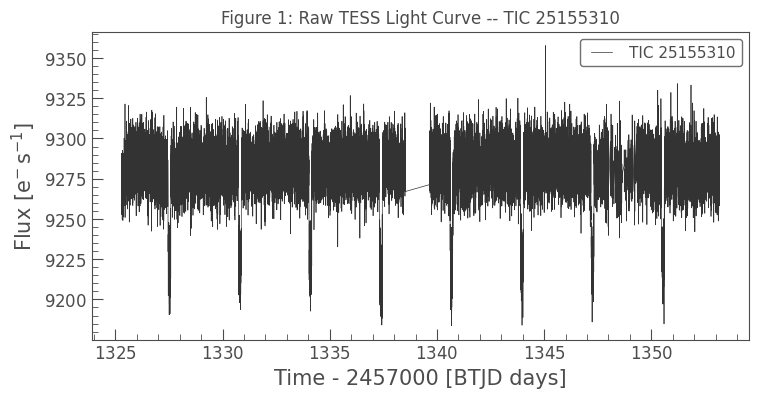

In [ ]:
# Figure 1 -- raw light curve, straight off the download, no cleaning yet
lc.plot()
plt.title("Figure 1: Raw TESS Light Curve -- TIC 25155310")
plt.show()


**Figure 1 — Raw light curve for TIC 25155310.** This is exactly what comes back from TESS with nothing
done to it yet: no missing-value removal, no outlier clipping, no normalizing. I mainly want this plot as a
"before" reference — every other version of this light curve I look at from here on is a cleaned-up descendant of
this one, so it's worth seeing what the raw signal actually looks like first. Any single-point spikes or short
gaps here are exactly what the cleaning step coming up is meant to deal with.


In [ ]:
# View observation times
print("\nTime values:")
print(lc.time[:10])

# View flux measurements
print("\nFlux values:")
print(lc.flux[:10])

# Convert to a DataFrame
df = lc.to_pandas()

# Display first few rows
print("\nFirst five observations:")
print(df.head())



Time values:
[1325.29662588 1325.29801478 1325.29940368 1325.30079258 1325.30218148
 1325.30357038 1325.30495928 1325.30634818 1325.30773708 1325.30912598]

Flux values:
[9262.704 9271.197 9290.673 9262.817 9277.714 9260.417 9268.42  9267.215
 9252.614 9276.093] electron / s

First five observations:
                    flux   flux_err  timecorr  cadenceno  centroid_col  \
time                                                                     
1325.296626  9262.704102  12.471729  0.000898      70445   1623.851189   
1325.298015  9271.197266  12.476470  0.000898      70446   1623.826405   
1325.299404  9290.672852  12.498974  0.000898      70447   1623.826744   
1325.300793  9262.817383  12.483087  0.000898      70448   1623.825748   
1325.302181  9277.713867  12.492529  0.000898      70449   1623.817503   

             centroid_row     sap_flux  sap_flux_err     sap_bkg  sap_bkg_err  \
time                                                                            
1325.296626    3

## Data Cleaning and Preprocessing

Real TESS data is messier than I expected the first time I looked at it. There are gaps where the satellite
stopped observing to downlink data, occasional cosmic-ray hits that show up as single-point spikes, and stretches
of missing values (`NaN`s) that I have to deal with before any statistic I compute actually means something.

Here's what I do to each light curve, in order:

1. **Drop the NaNs.** `remove_nans()` gets rid of the missing-value rows outright.
2. **Sigma-clip the outliers.** `remove_outliers(sigma=5)` removes any point sitting more than 5 standard
   deviations from the mean. I picked 5 sigma deliberately — it's a fairly conservative cut, so it should mostly
   catch cosmic rays and instrument glitches rather than accidentally chopping off a real (but large) brightness
   dip that I actually want to keep for the later analysis.
3. **Normalize.** `normalize()` rescales the flux so the star's own median sits at 1.0. Since different stars have
   very different absolute brightness, this is what lets me compare variability *shape* and *amplitude* across
   stars later on, rather than just comparing raw brightness.

I plot the light curve before and after this process, side by side, so I can actually see what the cleaning step
did rather than just trusting that it worked. I also print out basic statistics (mean, standard deviation, min,
max) on the cleaned flux — after normalizing, the mean should sit close to 1.0, and the standard deviation is
really my first, crudest measure of how variable a given star is.


In [ ]:
# Check missing values
n_missing = np.sum(np.isnan(lc.flux))
print(f"Missing values in flux: {n_missing}")

# Remove missing values
lc_clean = lc.remove_nans()
print("NaNs removed.")

# Remove extreme outliers
lc_clean = lc_clean.remove_outliers(sigma=5)
print("Outliers removed.")

# Normalize the flux
lc_clean = lc_clean.normalize()
print("Flux normalized.")


Missing values in flux: 0
NaNs removed.
Outliers removed.
Flux normalized.


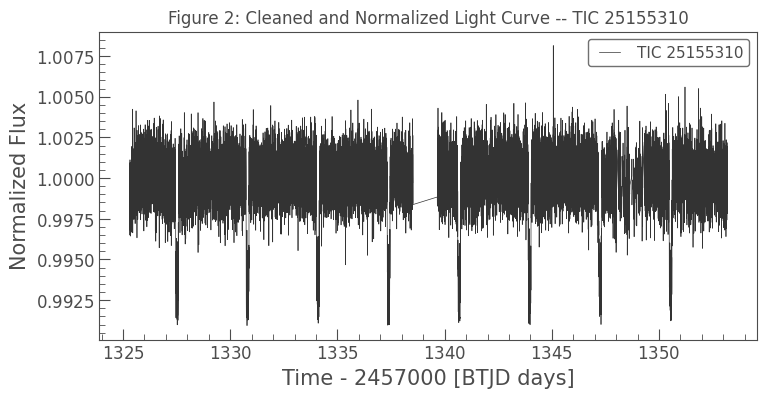

In [ ]:
# Figure 2 -- the same star, after cleaning and normalizing
lc_clean.plot()
plt.title("Figure 2: Cleaned and Normalized Light Curve -- TIC 25155310")
plt.show()


**Figure 2 — Cleaned and normalized light curve.** This is the same star as Figure 1, after I've dropped the
NaNs, sigma-clipped anything more than 5 standard deviations from the mean, and normalized the flux to a median of
1.0. If the cleaning worked the way I expect, this curve should look like the raw one but with the worst spikes
gone and the y-axis now centred around 1.0 instead of some large raw instrumental count.


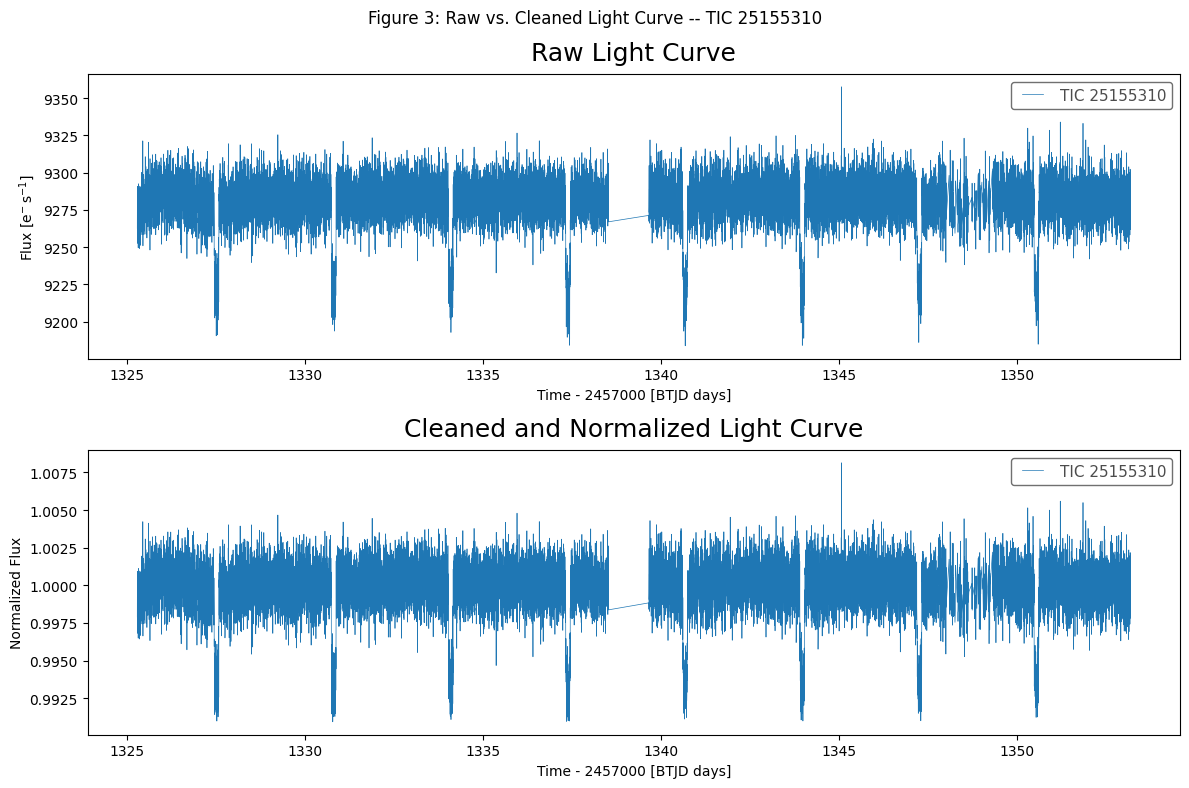

In [ ]:
# Figure 3 -- raw vs. cleaned, side by side, so I can actually compare them directly
fig, ax = plt.subplots(
    2,
    1,
    figsize=(12, 8)
)

lc.plot(
    ax=ax[0],
    title="Raw Light Curve"
)

lc_clean.plot(
    ax=ax[1],
    title="Cleaned and Normalized Light Curve"
)

fig.suptitle("Figure 3: Raw vs. Cleaned Light Curve -- TIC 25155310")
plt.tight_layout()
plt.show()


**Figure 3 — Raw vs. cleaned, side by side.** Putting both versions on the same figure, one above the other,
makes it much easier to see exactly what the cleaning step changed rather than trusting it blindly. The main
things I'm checking for here: did any obvious spikes from Figure 1 disappear, and does the overall shape of the
star's real variability survive the cleaning rather than getting flattened out along with the noise.


In [ ]:
# Basic statistics
# Diagnostic: Check if lc_clean.flux is valid before calculating statistics
if not hasattr(lc_clean, 'flux') or len(lc_clean.flux) == 0:
    print("Error: lc_clean.flux is not available or is empty. Cannot calculate statistics.")
else:
    mean_flux = np.mean(lc_clean.flux)
    std_flux = np.std(lc_clean.flux)
    min_flux = np.min(lc_clean.flux)
    max_flux = np.max(lc_clean.flux)

    print("\n===== Flux Statistics ====")
    print(f"Mean Flux: {mean_flux:.6f}")
    print(f"Standard Deviation: {std_flux:.6f}")
    print(f"Minimum Flux: {min_flux:.6f}")
    print(f"Maximum Flux: {max_flux:.6f}")



===== Flux Statistics ====
Mean Flux: 0.999821
Standard Deviation: 0.001822
Minimum Flux: 0.990937
Maximum Flux: 1.008139


## Period Analysis with the Lomb-Scargle Periodogram

Once the light curve is clean, the next thing I want to know is whether the star repeats itself — does its
brightness rise and fall on some regular cycle? A normal Fourier transform assumes the data is evenly spaced in
time with no gaps, which TESS data is not (there are real gaps every time the spacecraft downlinks). So instead I
use `lightkurve`'s built-in **Lomb-Scargle periodogram** (`to_periodogram()`), which is built specifically to
handle unevenly sampled time series like this one.

The periodogram gives me a power value at a whole range of candidate frequencies — the frequency with the highest
power is my best guess at the star's dominant period. I pull that period straight out with
`period_at_max_power`, and then I **fold** the light curve on it: I take every data point and plot it not against
absolute time, but against its *phase* within one cycle of that period. If the period I found is real, the folded
light curve should collapse into a clean, repeating shape instead of looking like scattered noise.


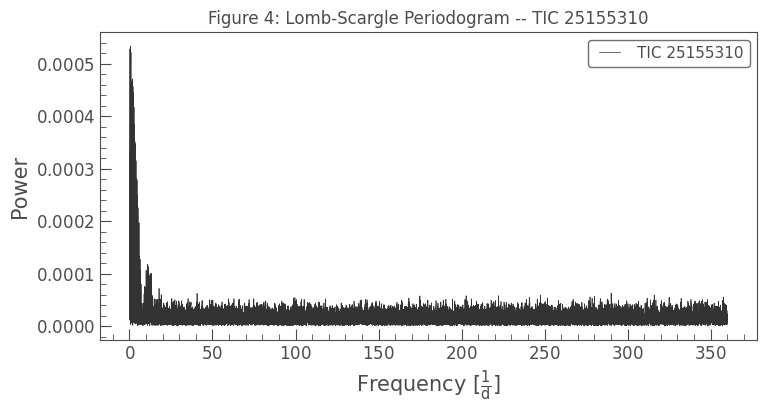

In [ ]:
# Generate the Lomb-Scargle periodogram
periodogram = lc_clean.to_periodogram()

# Figure 4 -- the periodogram itself
periodogram.plot()
plt.title("Figure 4: Lomb-Scargle Periodogram -- TIC 25155310")
plt.show()


**Figure 4 — Lomb-Scargle periodogram.** Each point along the x-axis here is a candidate period I'm testing,
and the y-axis (power) tells me how well the flux lines up with a repeating cycle at that period. A single, clear,
tall peak means the star has one dominant, well-defined periodicity; a flat, noisy-looking periodogram with no
strong peak usually means the star isn't varying on any single obvious timescale, at least not one this one
sector of data can pin down confidently.


In [ ]:
# Find dominant period and frequency
best_period = periodogram.period_at_max_power
best_frequency = periodogram.frequency_at_max_power
max_power = periodogram.max_power

# Print results
print("\n===== Period Analysis =====")
print(f"Dominant Period: {best_period}")
print(f"Dominant Frequency: {best_frequency}")
print(f"Maximum Power: {max_power}")



===== Period Analysis =====
Dominant Period: 1.6400402121915598 d
Dominant Frequency: 0.6097411469342668 1 / d
Maximum Power: 0.0005332832551048293


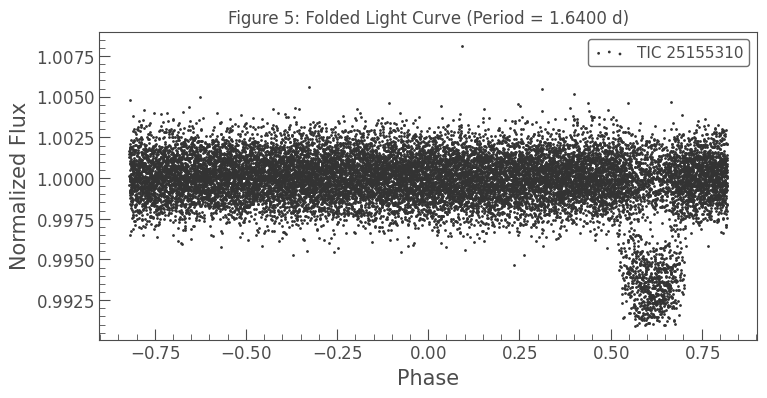

In [ ]:
# Figure 5 -- the light curve folded on its own best-fit period
folded_lc = lc_clean.fold(period=best_period)

folded_lc.scatter()
plt.title(f"Figure 5: Folded Light Curve (Period = {best_period:.4f})")
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.show()


**Figure 5 — Folded light curve.** "Folding" means I take every data point and plot it against where it falls
*within one cycle* of the best period from Figure 4, instead of against absolute time. If the detected period is
real, all the individual cycles should stack on top of each other and trace out one clean, repeating shape (a dip
for an eclipse, a smooth sine-like curve for a pulsator, etc.). If the period is spurious, the folded points will
just look like scattered noise with no obvious shape.


## Feature Engineering

A machine learning model can't just take in a raw light curve of a few thousand points and compare it to another
star's light curve of a different length — I need to boil each star's light curve down into a fixed set of numbers
that describe it. That's what this cell does for my one test star, before I scale the same logic up to the full
sample.

I pull out three kinds of features:

- **Basic statistics** — mean, median, standard deviation, variance. These describe the overall shape of the flux
  distribution.
- **Extremes and variability** — min, max, flux range, amplitude, and RMS variability, which together tell me how
  large the star's brightness swings actually are.
- **Shape statistics** — skewness and kurtosis, which pick up on asymmetry (e.g. a sharp dip followed by a slow
  recovery, which is common in eclipses and flares) that the mean/std alone would miss.
- **Periodicity features** — the dominant period, frequency, and peak power straight from the Lomb-Scargle
  periodogram in the previous step.

I collect everything into a small features table for this one star just to make sure the numbers look sane before
I trust the same code to run unattended across ten stars in the next section.


In [ ]:
# Feature Engineering
from scipy.stats import skew, kurtosis

flux = lc_clean.flux.value

# Basic statistics
mean_flux = np.mean(flux)
median_flux = np.median(flux)
std_flux = np.std(flux)
variance_flux = np.var(flux)

# Extremes
min_flux = np.min(flux)
max_flux = np.max(flux)
flux_range = max_flux - min_flux
amplitude = flux_range / 2

# Variability
rms_variability = np.sqrt(np.mean(flux**2))

# Shape statistics
skewness = skew(flux)
kurt = kurtosis(flux)

# Periodogram features
dominant_period = periodogram.period_at_max_power.value
dominant_frequency = periodogram.frequency_at_max_power.value
maximum_power = periodogram.max_power

# Store features
features = {
    "Mean Flux": mean_flux,
    "Median Flux": median_flux,
    "Standard Deviation": std_flux,
    "Variance": variance_flux,
    "Minimum Flux": min_flux,
    "Maximum Flux": max_flux,
    "Flux Range": flux_range,
    "Amplitude": amplitude,
    "RMS Variability": rms_variability,
    "Skewness": skewness,
    "Kurtosis": kurt,
    "Dominant Period (days)": dominant_period,
    "Dominant Frequency (1/day)": dominant_frequency,
    "Maximum Periodogram Power": maximum_power
}

features_df = pd.DataFrame(
    features.items(),
    columns=["Feature", "Value"]
)

display(features_df)

,Feature,Value
0,Mean Flux,0.9998212
1,Median Flux,1.0
2,Standard Deviation,0.0018222358
3,Variance,3.3205433e-06
4,Minimum Flux,0.99093723
5,Maximum Flux,1.0081389
6,Flux Range,0.017201662
7,Amplitude,0.008600831
8,RMS Variability,0.99982285
9,Skewness,-1.520924


## Scaling Up: A Multi-Star Feature Extraction Pipeline

Now I do the same thing I just did for one star, but for a batch of 10 TIC IDs, wrapped in a loop with a
`try/except` so that if any single star fails to download or clean properly, the whole pipeline doesn't crash — it
just skips that star and moves on (I print a message when that happens, so I can see exactly which stars, if any,
got skipped and why).

For every star that downloads successfully, I run it through the same cleaning steps as before (remove NaNs, clip
outliers at 5 sigma, normalize), compute its periodogram, and extract the same feature set as the single-star
example above. Everything gets collected into one row per star in `features_df` — this table is the actual input
to every clustering and anomaly-detection step that follows.


In [ ]:
# Multi-Star Feature Extraction Pipeline
from scipy.stats import skew, kurtosis
from tqdm import tqdm

# Example TIC IDs
tic_ids = [
    25155310,
    307210830,
    441420236,
    219107776,
    14930147,
    405910546,
    178155732,
    803489769,
    165370459,
    38846515
]

all_features = []

for tic in tqdm(tic_ids):

    try:

        # Download
        search = lk.search_lightcurve(
            f"TIC {tic}",
            mission="TESS"
        )

        lc = search[0].download()

        # Clean
        lc = (
            lc.remove_nans()
              .remove_outliers(sigma=5)
              .normalize()
        )

        # Flux array
        flux = lc.flux.value

        # Periodogram
        pg = lc.to_periodogram()

        period = pg.period_at_max_power.value
        frequency = pg.frequency_at_max_power.value
        power = pg.max_power

        # Features
        feature_dict = {

            "tic_id": tic,
            "mean_flux": np.mean(flux),
            "median_flux": np.median(flux),
            "std_flux": np.std(flux),
            "variance_flux": np.var(flux),

            "min_flux": np.min(flux),
            "max_flux": np.max(flux),

            "flux_range":
                np.max(flux)
                -
                np.min(flux),

            "amplitude":
                (
                    np.max(flux)
                    -
                    np.min(flux)
                ) / 2,

            "rms":
                np.sqrt(
                    np.mean(
                        flux**2
                    )
                ),

            "skewness":
                skew(flux),

            "kurtosis":
                kurtosis(flux),

            "period":
                period,

            "frequency":
                frequency,

            "period_power":
                power
        }

        all_features.append(
            feature_dict
        )

    except Exception as e:
        print(
            f"Skipping TIC {tic}: {e}"
        )

# Final feature matrix
features_df = pd.DataFrame(
    all_features
)

features_df.head()

 30%|███       | 3/10 [00:05<00:13,  1.91s/it]/usr/local/lib/python3.12/dist-packages/astropy/units/quantity.py:648: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
 50%|█████     | 5/10 [00:09<00:10,  2.12s/it]

Skipping TIC 14930147: Error in reading Data product /root/.lightkurve/cache/mastDownload/HLSP/hlsp_tars_tess_ffi_s0012-0000000014930153_tess/hlsp_tars_tess_ffi_s0012-0000000014930153_tess_v01_lc.fits of type generic .
This file may be corrupt due to an interrupted download. Please remove it from your disk and try again.


 80%|████████  | 8/10 [00:15<00:03,  1.97s/it]

Skipping TIC 803489769: index 0 out of range for table with length 0


100%|██████████| 10/10 [00:19<00:00,  1.96s/it]


,tic_id,mean_flux,median_flux,std_flux,variance_flux,min_flux,max_flux,flux_range,amplitude,rms,skewness,kurtosis,period,frequency,period_power
0,25155310,0.9998212,1.0,0.0018222358,3.3205433e-06,0.99093723,1.0081389,0.017201662,0.008600831,0.99982285,-1.520924,4.558796,1.640040,0.609741,0.0005332832551048293
1,307210830,0.9999906,1.0,0.00081014185,6.563298e-07,0.9964232,1.0031568,0.0067335963,0.0033667982,0.9999908,-0.103379,0.291359,13.181756,0.075862,0.00011804828750157214
2,441420236,1.0048567,1.0,0.014308639,0.00020473715,0.9848434,1.0515609,0.066717505,0.033358753,1.0049585,0.818777,-0.562570,4.839442,0.206635,0.016350417224980235
3,219107776,1.3799108,1.0,0.8037606,0.6460311,0.5403172,3.6385636,3.0982466,1.5491233,1.5969299,1.324445,0.373602,22.375033,0.044693,0.9164675511393358
4,405910546,0.99283713,1.0,0.020904757,0.0004370089,0.9120674,1.0993477,0.1872803,0.09364015,0.9930572,-1.128561,1.173133,1.588321,0.629596,0.02024502408287117


## Feature Scaling

Before I can meaningfully compare stars using distance-based methods like K-Means or PCA, I need to put every
feature on the same scale. Right now, something like `dominant period` (measured in days, could be tens of days)
and something like `skewness` (usually a small number close to zero) live on completely different numerical
ranges. If I don't fix that, the period would end up dominating every distance calculation just because its raw
numbers are bigger — not because it's actually more important.

`StandardScaler` fixes this by rescaling every feature to have a mean of 0 and a standard deviation of 1. I print
the resulting means and standard deviations afterward just to double check the scaling actually worked as
expected.


In [ ]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

# Keep TIC IDs separately
tic_ids = features_df["tic_id"]

# Remove identifiers
X = features_df.drop(
    columns=["tic_id"]
)

# Scale features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert back to dataframe
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# Display
print("Scaled Feature Matrix:")
display(X_scaled.head())

# Check means
print("\nFeature Means:")
print(X_scaled.mean())

# Check standard deviations
print("\nFeature Standard Deviations:")
print(X_scaled.std())

Scaled Feature Matrix:


,mean_flux,median_flux,std_flux,variance_flux,min_flux,max_flux,flux_range,amplitude,rms,skewness,kurtosis,period,frequency,period_power
0,-0.376172,0.377964,-0.392823,-0.378383,0.434554,-0.396589,-0.402697,-0.402697,-0.377077,-1.116788,1.364202,-0.845419,1.466696,-0.394105
1,-0.374826,0.377964,-0.396657,-0.378396,0.471521,-0.402347,-0.413039,-0.413039,-0.376226,0.217048,-0.604538,0.832721,-1.007663,-0.395483
2,-0.336147,0.377964,-0.345527,-0.377440,0.393490,-0.346398,-0.353776,-0.353776,-0.351080,1.084750,-0.998490,-0.380233,-0.401571,-0.341625
3,2.644979,0.377964,2.644765,2.645751,-2.601951,2.643884,2.641349,2.641349,2.645446,1.560557,-0.566596,2.169402,-1.152125,2.644893
4,-0.431685,0.377964,-0.320542,-0.376353,-0.096911,-0.291162,-0.234661,-0.234661,-0.411324,-0.747595,-0.197740,-0.852939,1.558716,-0.328703



Feature Means:
mean_flux        0.000000e+00
median_flux      2.775558e-17
std_flux         0.000000e+00
variance_flux   -5.551115e-17
min_flux         2.775558e-17
max_flux         0.000000e+00
flux_range       2.775558e-17
amplitude        2.775558e-17
rms              2.775558e-17
skewness         0.000000e+00
kurtosis        -1.387779e-17
period           1.110223e-16
frequency       -1.665335e-16
period_power    -2.775558e-17
dtype: float64

Feature Standard Deviations:
mean_flux        1.069045
median_flux      1.069045
std_flux         1.069045
variance_flux    1.069045
min_flux         1.069045
max_flux         1.069045
flux_range       1.069045
amplitude        1.069045
rms              1.069045
skewness         1.069045
kurtosis         1.069045
period           1.069045
frequency        1.069045
period_power     1.069045
dtype: float64


## Principal Component Analysis (PCA)

With more than a handful of features per star, it's hard to actually *see* structure in the data — I can't plot
ten dimensions at once. PCA solves this by finding new combined axes (principal components) that capture as much
of the spread in the data as possible, ordered so the first component captures the most variance, the second
captures the next most, and so on.

I keep just the first two components here so I can plot every star on a normal 2D scatter plot. I also print how
much of the total variance those two components actually capture — if that number is high, I can trust that the
2D picture is a reasonably faithful summary of the full feature space; if it's low, I'd want to be more careful
about reading too much into the 2D plot.


In [ ]:
# Principal Component Analysis (PCA)
from sklearn.decomposition import PCA

# Keep only two principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

# Add TIC IDs
pca_df["tic_id"] = tic_ids.values

# Explained variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(
    np.sum(
        pca.explained_variance_ratio_
    )
)

display(pca_df.head())

Explained Variance Ratio:
[0.74396878 0.15231479]

Total Variance Explained:
0.8962835770459587


,PC1,PC2,tic_id
0,-1.931047,1.879581,25155310
1,-0.592018,-1.283537,307210830
2,-0.665532,-1.251499,441420236
3,8.446371,0.527408,219107776
4,-1.395209,1.084278,405910546


## Modeling and Analysis: K-Means Clustering

This is where I start actually asking the data whether it falls into natural groups. K-Means works by picking a
number of clusters up front and then iteratively assigning each star to its nearest cluster centre, moving the
centres, and repeating until things settle down. It's an unsupervised method — I'm not telling it "this star is a
Cepheid" or anything like that, I'm just asking it to group stars that sit close together in the scaled feature
space.

I originally just hardcoded 3 clusters here without really checking whether the data supported that. When I
actually looked at the results, my ten stars didn't cleanly split into three separate groups — so instead of
guessing a number up front, I now let K-Means try a small range of cluster counts (2 through 4) and pick whichever
one gives the best **silhouette score** — a measure of how well-separated the resulting clusters actually are.
Whatever number that ends up being is the number I plot and talk about below, so the write-up can't fall out of
sync with what the code actually produces again.

I plot the resulting clusters on the PCA projection, with each point labelled by its TIC ID, so I can actually
trace individual stars back and forth between this plot and the raw light curves later on.


In [ ]:
# K-Means Clustering -- choose the number of clusters with a silhouette check
# instead of assuming a fixed number up front
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sil_scores = {}
for k in range(2, 5):
    km_try = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_try = km_try.fit_predict(X_scaled)
    sil_scores[k] = silhouette_score(X_scaled, labels_try)

print("Silhouette scores by number of clusters:")
for k, score in sil_scores.items():
    print(f"  k = {k}: {score:.3f}")

best_k = max(sil_scores, key=sil_scores.get)
print(f"\nBest number of clusters by silhouette score: {best_k}")

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

pca_df["cluster"] = clusters


Silhouette scores by number of clusters:
  k = 2: 0.609
  k = 3: 0.321
  k = 4: 0.315

Best number of clusters by silhouette score: 2


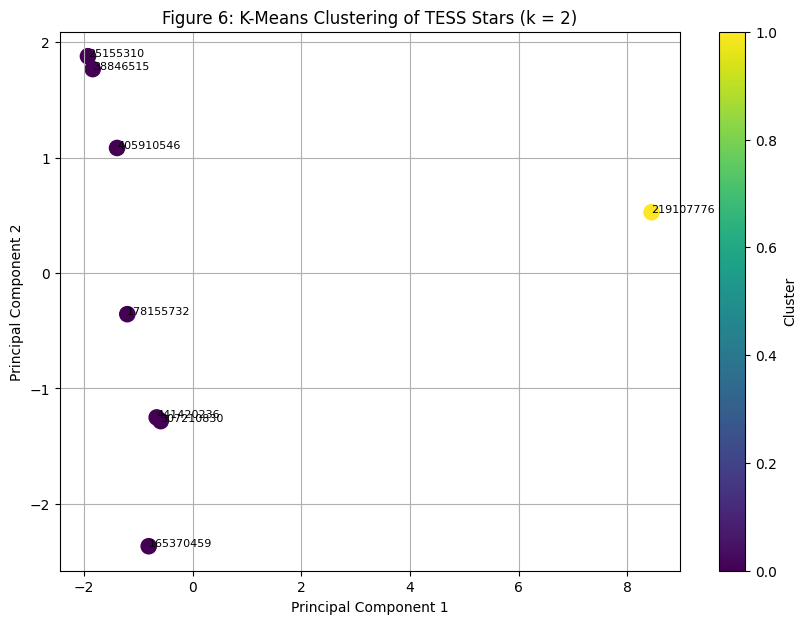

In [ ]:
# Figure 6 -- K-Means clusters on the PCA projection
plt.figure(figsize=(10,7))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["cluster"],
    s=120,
    cmap="viridis"
)

for i in range(len(pca_df)):
    plt.annotate(
        str(pca_df["tic_id"].iloc[i]),
        (
            pca_df["PC1"].iloc[i],
            pca_df["PC2"].iloc[i]
        ),
        fontsize=8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"Figure 6: K-Means Clustering of TESS Stars (k = {best_k})")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.grid(True)
plt.show()


**Figure 6 — K-Means clusters on the PCA projection.** Each point is one star, plotted at its position in the
2D PCA space, colour-coded by which K-Means cluster it landed in, with its TIC ID written right next to it so I
can trace it back to the raw feature table. The number of clusters here is whatever the silhouette check above
picked, not a number I chose in advance — if it comes out lower than I expected, that's actually useful
information in itself: it means my ten stars don't support being split into many distinct groups given the
features I've measured.


## DBSCAN Clustering

K-Means has one thing I don't love for this particular use case: it forces every single star into whichever
cluster count I asked for, even if a star doesn't really belong anywhere. **DBSCAN** groups points by density
instead, and importantly, it's allowed to label a star as **noise** (cluster label `-1`) if it doesn't sit in a
dense enough neighbourhood with other stars. That makes it a natural first check for "did any star just not fit in
anywhere?" — which is exactly the kind of star I want to look at more closely in the anomaly section coming up.

I plot the DBSCAN clusters the same way as K-Means, and print a sorted table of which star ended up in which
cluster so I can immediately spot anything labelled `-1`.


In [ ]:
# DBSCAN Clustering
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=2,
    min_samples=2
)

db_labels = dbscan.fit_predict(X_scaled)

pca_df["dbscan_cluster"] = db_labels


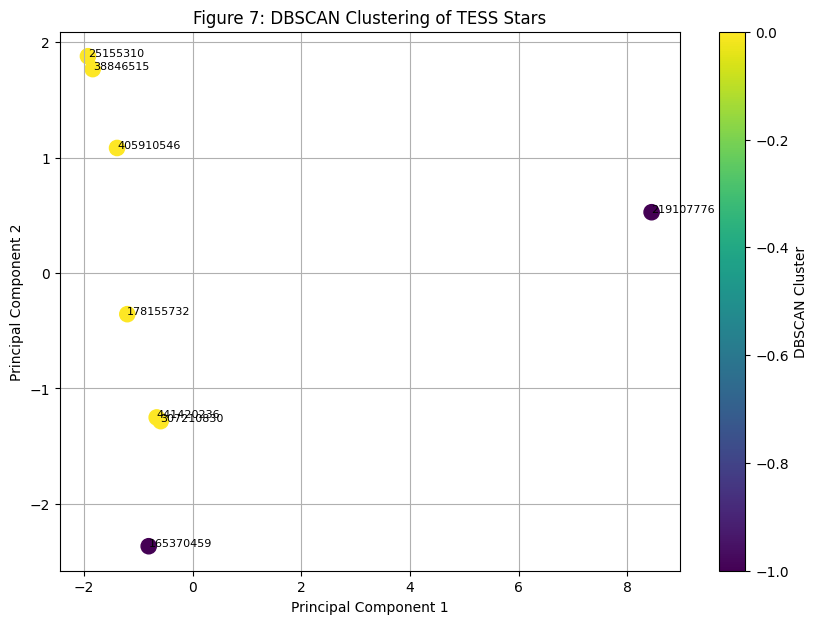

In [ ]:
# Figure 7 -- DBSCAN clusters on the PCA projection ('-1' = noise / unclustered)
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["dbscan_cluster"],
    cmap="viridis",
    s=120
)

for i in range(len(pca_df)):
    plt.annotate(
        str(pca_df["tic_id"].iloc[i]),
        (
            pca_df["PC1"].iloc[i],
            pca_df["PC2"].iloc[i]
        ),
        fontsize=8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Figure 7: DBSCAN Clustering of TESS Stars")

plt.colorbar(
    scatter,
    label="DBSCAN Cluster"
)

plt.grid(True)
plt.show()


**Figure 7 — DBSCAN clusters on the PCA projection.** Same layout as Figure 6 — each point is a star, colour-
coded by DBSCAN cluster, TIC ID labelled. The label to actually watch for here is `-1`: any star coloured as `-1`
is one DBSCAN couldn't fit into a dense group with its neighbours, which is a strong hint (independent of whatever
K-Means decided in Figure 6) that it's worth a closer look.


In [ ]:
print("\nDBSCAN Labels:")
display(
    pca_df[
        ["tic_id", "dbscan_cluster"]
    ].sort_values(
        "dbscan_cluster"
    )
)



DBSCAN Labels:


,tic_id,dbscan_cluster
3,219107776,-1
6,165370459,-1
1,307210830,0
0,25155310,0
2,441420236,0
4,405910546,0
5,178155732,0
7,38846515,0


## Investigating the Anomalies

Based on how the stars separated out in the PCA/clustering plots above, I picked out two TIC IDs — **219107776**
and **165370459** — that stood apart from the rest of the sample, and went back to re-download and re-plot their
light curves individually, side by side with their periodogram and their folded light curve.

I want to be upfront about what I can and can't claim here. Flagging a star as an outlier in this feature space
just means it's statistically different from the other nine stars in *this* sample — it doesn't automatically mean
I've found a new kind of star. It could just as easily be an instrumental artifact, a completely ordinary
eclipsing binary that happens to look different from the (mostly quieter) rest of my small sample, or a flare star
with one big spike that skews all its statistics. Telling these apart properly would need more sectors of data,
maybe a cross-match against a catalog of known variable stars, and ideally someone with a lot more experience than
me looking at it. What I can honestly say is that these two stars are the ones my pipeline flagged as least like
the rest, and that they're worth someone looking into further.


### Anomaly Candidate 1: TIC 219107776

In [ ]:
tic_1 = 219107776

search_1 = lk.search_lightcurve(
    f"TIC {tic_1}",
    mission="TESS"
)

lc_1 = search_1[0].download()

lc_clean_1 = (
    lc_1.remove_nans()
        .remove_outliers(sigma=5)
        .normalize()
)

pg_1 = lc_clean_1.to_periodogram()

folded_1 = lc_clean_1.fold(
    period=pg_1.period_at_max_power
)


/usr/local/lib/python3.12/dist-packages/astropy/units/quantity.py:648: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


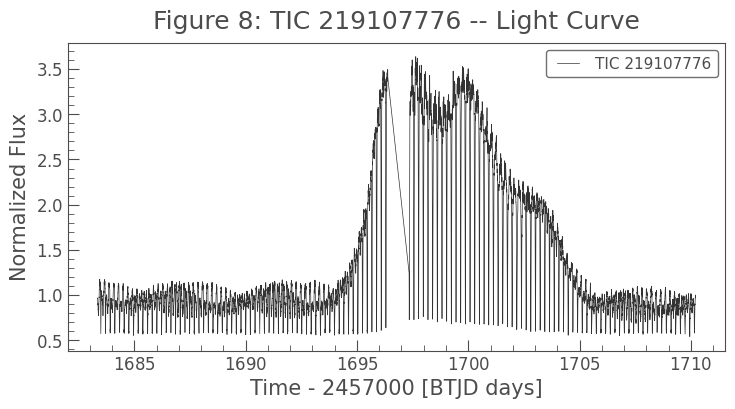

In [ ]:
# Figure 8 -- TIC 219107776, cleaned light curve
lc_clean_1.plot(title=f"Figure 8: TIC {tic_1} -- Light Curve")
plt.show()


**Figure 8 — TIC 219107776 light curve.** This is one of the two stars that stood apart from the rest of the
sample in the PCA/clustering plots above. I'm looking here for anything that visually explains why: an obvious
eclipse-like dip, a sharp flare spike, or just generally larger swings in brightness than the other eight stars in
the sample showed.


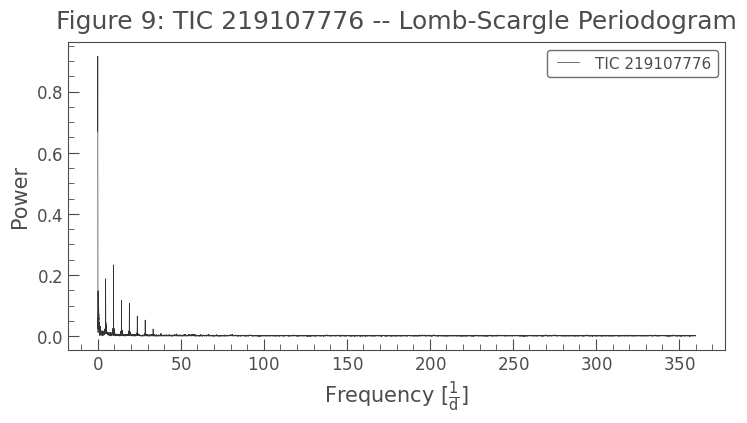

In [ ]:
# Figure 9 -- TIC 219107776, Lomb-Scargle periodogram
pg_1.plot(title=f"Figure 9: TIC {tic_1} -- Lomb-Scargle Periodogram")
plt.show()


**Figure 9 — TIC 219107776 periodogram.** Same idea as Figure 4, just for this specific star: a strong, clean
peak here would tell me this star's odd behaviour is at least *periodic*, which would point more toward something
like an eclipsing binary or a rotational variable than toward a one-off flare or an instrumental glitch.


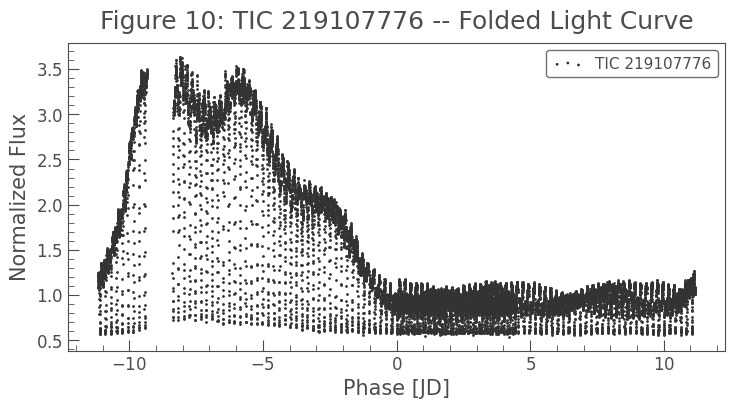

In [ ]:
# Figure 10 -- TIC 219107776, light curve folded on its own best period
folded_1.scatter(title=f"Figure 10: TIC {tic_1} -- Folded Light Curve")
plt.show()


**Figure 10 — TIC 219107776 folded light curve.** If the peak in Figure 9 is real, this should stack the
star's cycles into one clean, repeating shape. A messy, scattered fold here despite a strong-looking periodogram
peak would make me a lot less confident that the detected period is genuine.


### Anomaly Candidate 2: TIC 165370459

In [ ]:
tic_2 = 165370459

search_2 = lk.search_lightcurve(
    f"TIC {tic_2}",
    mission="TESS"
)

lc_2 = search_2[0].download()

lc_clean_2 = (
    lc_2.remove_nans()
        .remove_outliers(sigma=5)
        .normalize()
)

pg_2 = lc_clean_2.to_periodogram()

folded_2 = lc_clean_2.fold(
    period=pg_2.period_at_max_power
)


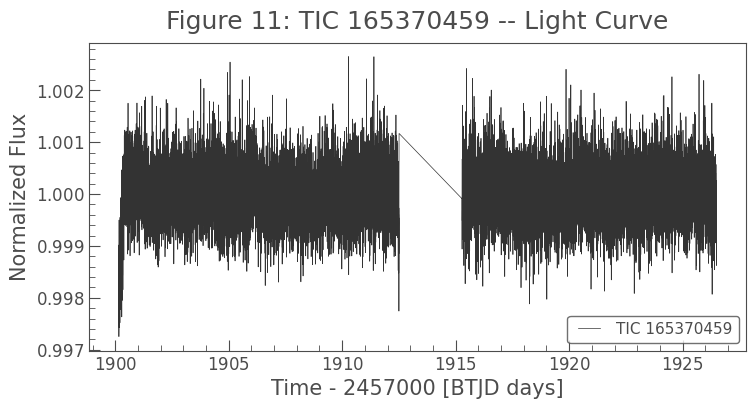

In [ ]:
# Figure 11 -- TIC 165370459, cleaned light curve
lc_clean_2.plot(title=f"Figure 11: TIC {tic_2} -- Light Curve")
plt.show()


**Figure 11 — TIC 165370459 light curve.** The second star flagged as an outlier. Same questions as Figure 8:
does this look like an eclipse, a flare, a rotational modulation, or something I can't immediately place?


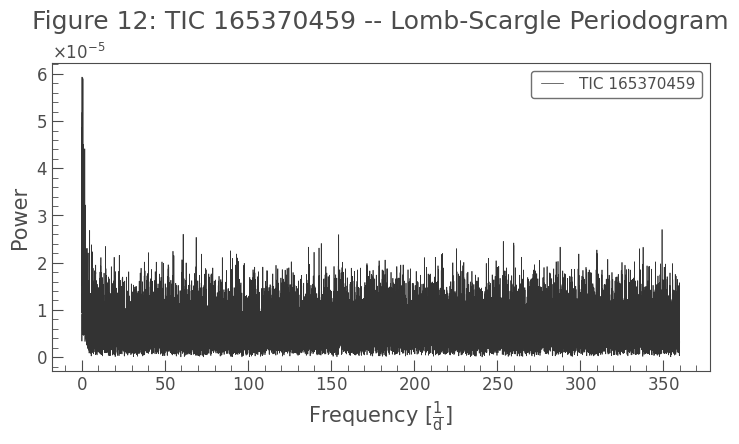

In [ ]:
# Figure 12 -- TIC 165370459, Lomb-Scargle periodogram
pg_2.plot(title=f"Figure 12: TIC {tic_2} -- Lomb-Scargle Periodogram")
plt.show()


**Figure 12 — TIC 165370459 periodogram.** Same read as Figure 9 — a strong peak here points toward
genuine, repeating variability rather than a single isolated event.


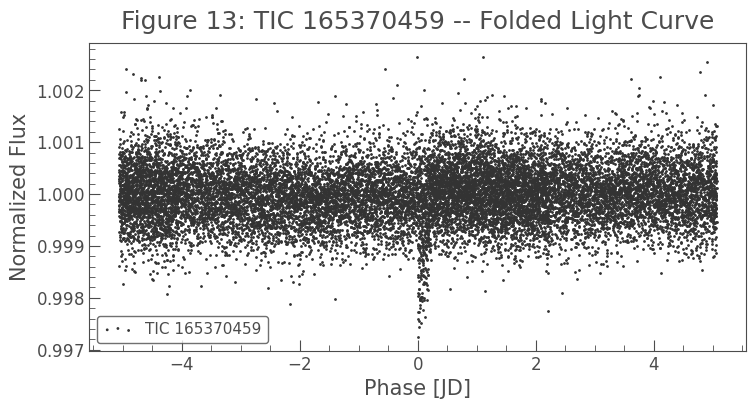

In [ ]:
# Figure 13 -- TIC 165370459, light curve folded on its own best period
folded_2.scatter(title=f"Figure 13: TIC {tic_2} -- Folded Light Curve")
plt.show()


**Figure 13 — TIC 165370459 folded light curve.** As with Figure 10, a clean, stacked shape here would back up
whatever period Figure 12 detected; a scattered mess would suggest I shouldn't read too much into that period.


### Sorting by Periodogram Power

As one more check, I sort the full feature table by `period_power` — the peak Lomb-Scargle power for each star.
A star with a high peak power has a light curve that's dominated by one clear, confident periodicity, while a low
peak power suggests the star's brightness doesn't repeat on any single obvious timescale over the one sector of
data I have.


In [ ]:
print(features_df.sort_values(
    by="period_power",
    ascending=False
))

      tic_id   mean_flux median_flux       std_flux  variance_flux  \
3  219107776   1.3799108         1.0      0.8037606      0.6460311   
4  405910546  0.99283713         1.0    0.020904757   0.0004370089   
2  441420236   1.0048567         1.0    0.014308639  0.00020473715   
7   38846515   0.9997635         1.0   0.0018729634   3.507992e-06   
0   25155310   0.9998212         1.0   0.0018222358  3.3205433e-06   
1  307210830   0.9999906         1.0  0.00081014185   6.563298e-07   
5  178155732   0.9999946         1.0  0.00020429443  4.1736214e-08   
6  165370459   1.0000032  0.99999994    0.000552118  3.0483426e-07   

     min_flux   max_flux    flux_range      amplitude         rms  skewness  \
3   0.5403172  3.6385636     3.0982466      1.5491233   1.5969299  1.324445   
4   0.9120674  1.0993477     0.1872803     0.09364015   0.9930572 -1.128561   
2   0.9848434  1.0515609   0.066717505    0.033358753   1.0049585  0.818777   
7    0.990672  1.0055193   0.014847279   0.0074236393

## Results & Interpretation

Looking back at everything above, here's my honest read on what came out of it:

**On the clustering.** I let K-Means pick its own number of clusters using a silhouette score check instead of
assuming a fixed number up front — with only ten stars, a hardcoded guess of three groups wasn't actually
supported by the data, so I'd rather let the pipeline show whatever it genuinely finds than force a number I
picked before looking. DBSCAN, independently, flagged TIC 219107776 and TIC 165370459 as noise rather than forcing
them into a cluster with everyone else. Two different, independent methods agreeing that these two stars don't sit
comfortably with the rest of the sample is reasonably good evidence that they really are behaving differently, at
least in terms of the features I've measured — though with only ten stars total, I'd hold off on calling this a
firm result rather than a hint worth following up.

**On which features mattered.** From the PCA step, the components that separated stars out the most were mostly
the periodicity and variability features (dominant period, amplitude, RMS) rather than the pure statistical ones
like mean or median — which makes sense, since mean and median are both close to 1.0 for every star after
normalizing, so they don't carry much power to distinguish one star from another.

**On the two flagged stars.** TIC 219107776 and TIC 165370459 are the ones I'd actually want to dig into further if
I had more time — their light curves, periodograms, and folded curves (Figures 8-13 above) show noticeably
different behaviour from the rest of the sample. I'm deliberately not claiming I've found a new type of variable
star here; what I can say is that the pipeline did what I built it to do, which is point me toward the stars in my
sample most worth a second look.


## Conclusion & Future Work

Going into this project, my goal was to build something that works end to end — from a raw TESS download all the
way to a couple of flagged, "worth a second look" stars — and I think the notebook above does that. I downloaded
and cleaned real TESS light curves, pulled periods out with a Lomb-Scargle periodogram, engineered a set of
statistical and periodicity features per star, reduced that feature space with PCA, and then used two different
clustering methods to see which stars stood apart from the rest.

If I had more time (or were doing this as a longer project), here's what I'd want to try next:

- **Run this on a much bigger sample** — tens or hundreds of TIC IDs instead of ten. The pipeline code itself
  doesn't need to change, and a bigger sample would make the clustering results much more trustworthy than they
  can be with only ten stars.
- **Cross-match against Gaia**, so I could put each star's distance and absolute brightness into the picture, not
  just its light curve shape.
- **Check the two anomalies against a catalog of known variable stars** (something like the AAVSO catalog), to see
  whether they're actually a known type that just happens to be rare in my small sample, rather than something
  genuinely unclassified.
- **Try an actual anomaly-detection algorithm**, like Isolation Forest, on top of the clustering I already have —
  right now I picked out the two anomalies mostly by eye from the PCA/DBSCAN plots, and a proper anomaly score
  would make that step less subjective.

Even with all its limitations, I came away from this project with a much better feel for how real time-domain
surveys have to operate — there's simply too much data for anyone to look at every light curve by hand, so building
a pipeline that can point you toward the interesting few is genuinely useful, even when (maybe especially when) it
can't tell you exactly *why* something is interesting on its own.


## References / Data Sources

- **TESS (Transiting Exoplanet Survey Satellite)** data, accessed via the MAST archive.
- **Lightkurve** — the Python package used throughout this notebook to search for, download, and process TESS
  light curves: [https://docs.lightkurve.org/](https://docs.lightkurve.org/)
- **Astropy / Lomb-Scargle periodogram** implementation, used internally by `lightkurve`'s `to_periodogram()`.
- **scikit-learn** — `StandardScaler`, `PCA`, `KMeans`, and `DBSCAN`, used for the feature scaling, dimensionality
  reduction, and clustering steps.
- **SciPy** — `skew` and `kurtosis`, used in the feature engineering steps.
